# AK-MCS-U vs NH-AK-MCS-U 결과 비교

아래 `RUN_DIR`의 **완료된 두 run**을 비교합니다. 두 `summary.json`이 모두 있어야 실행됩니다. 실제 g 기반 신뢰성 지표는 별도 독립 표본에서 계산합니다.

비교 기준은 실제 한계상태함수 호출 수(`n_true_calls`)입니다. 동일 호출 수의 추이를 비교하며, 최종 결과는 양쪽 summary에서 읽습니다. `Pf`는 서로 다른 surrogate의 추정값이고, MC CoV는 **surrogate에 조건부인** 표본오차입니다. 둘 다 정확도 보증으로 해석하지 않습니다.

In [13]:
from pathlib import Path
import hashlib
import html
import json
import math

RUN_DIR = Path("runs/gp_holdout_01")
MODES = {"reference": "AK-MCS-U", "nh": "NH-AK-MCS-U"}
COLORS = {"reference": "#2563eb", "nh": "#e87924"}

try:
    from IPython.display import HTML, SVG, display
except ImportError:  # 표준 Python에서 계산 검증할 때
    HTML = SVG = display = None

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def show_html(markup):
    if display is None:
        print(html.unescape(markup.replace("<tr>", "\n").replace("</td>", "  ").replace("<th>", "  ").replace("</th>", "  ").replace("</tr>", "").replace("<table>", "").replace("</table>", "")))
    else:
        display(HTML(markup))

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th style='text-align:left;padding:5px 12px;border-bottom:1px solid #aaa'>{cell(v)}</th>" for v in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:4px 12px'>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    show_html(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")

def fmt(value, digits=5):
    if value is None:
        return "—"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, (float, int)):
        return f"{value:.{digits}f}"
    return str(value)

runs = {}
for mode in MODES:
    folder = RUN_DIR / mode
    required = ["summary.json", "evaluation.jsonl", "g_calls.jsonl", "selection.jsonl", "effective_config.json", "initial_design.json", "fixed_samples.json"]
    missing = [name for name in required if not (folder / name).is_file()]
    if missing:
        raise FileNotFoundError(f"{folder}: 완료된 run에 필요한 파일이 없습니다: {', '.join(missing)}")
    runs[mode] = {
        "summary": read_json(folder / "summary.json"),
        "evaluation": read_jsonl(folder / "evaluation.jsonl"),
        "g_calls": read_jsonl(folder / "g_calls.jsonl"),
        "selection": read_jsonl(folder / "selection.jsonl"),
        "config": read_json(folder / "effective_config.json"),
        "initial": read_json(folder / "initial_design.json"),
        "samples_hash": sha256(folder / "fixed_samples.json"),
    }
    if not runs[mode]["evaluation"]:
        raise ValueError(f"{folder}: evaluation.jsonl이 비어 있습니다.")
print(f"완료된 run 로드: {RUN_DIR} / " + ", ".join(MODES.values()))

완료된 run 로드: runs\gp_holdout_01 / AK-MCS-U, NH-AK-MCS-U


## 비교 가능성 확인

두 모드의 시작 설계, MC 표본, 난수 시드와 호출 예산이 같아야 paired 비교가 성립합니다. 아래 항목이 하나라도 다르면 결과 해석에 주의하세요.

In [14]:
ref, nh = runs["reference"], runs["nh"]
checks = {
    "초기 X/Y 동일": all(ref["initial"].get(k) == nh["initial"].get(k) for k in ("X", "Y")),
    "고정 MC 표본 동일": ref["samples_hash"] == nh["samples_hash"],
    "시드 동일": ref["config"].get("seed") == nh["config"].get("seed"),
    "초기 MC 크기 동일": ref["config"]["evaluation"].get("integration_size") == nh["config"]["evaluation"].get("integration_size"),
    "true-call 예산 동일": ref["config"]["evaluation"].get("max_true_calls") == nh["config"]["evaluation"].get("max_true_calls"),
}
table(["검사", "결과"], [(name, "일치" if ok else "불일치") for name, ok in checks.items()])
if not all(checks.values()):
    print("주의: paired 조건이 완전히 일치하지 않습니다.")
for mode, run in runs.items():
    recorded = len(run["g_calls"])
    reported = run["summary"]["n_true_calls"]
    final = run["summary"]["final"]
    assert recorded == reported == final["n_true_calls"], (mode, recorded, reported, final["n_true_calls"])
    assert run["evaluation"][-1]["n_true_calls"] == reported, mode
print("호출 로그, 마지막 평가, summary의 true-call 수 일치.")

검사,결과
초기 X/Y 동일,일치
고정 MC 표본 동일,일치
시드 동일,일치
초기 MC 크기 동일,일치
true-call 예산 동일,일치


호출 로그, 마지막 평가, summary의 true-call 수 일치.


## 최종 결과

`converged`는 학습 종료 기준(min U ≥ 목표값)과 MC 정밀도 기준을 **모두** 만족한 경우입니다. `budget_exhausted`는 주어진 호출 예산에서 중단됐다는 뜻입니다.

In [15]:
stop = ref["config"]["evaluation"]["stop"]
paper = ref["config"].get("reference", {}).get("paper_example", {})
rows = []
for mode, run in runs.items():
    s, f = run["summary"], run["summary"]["final"]
    rows.append((
        MODES[mode], s["n_true_calls"], fmt(f["pf_surrogate"]), fmt(f["population_min_u"], 3),
        fmt(f["mc_cov"], 4), f["learning_converged"], f["mc_precision_met"],
        f["converged"], f["stop_reason"], fmt(s.get("wall_seconds"), 1)
    ))
table(["모드", "true calls", "Pf", "min U", "MC CoV", "학습 수렴", "MC 정밀도", "전체 수렴", "중단 이유", "시간(s)"], rows)
print(f"설정 기준: min U ≥ {stop['min_u']}, MC CoV ≤ {stop['max_mc_cov']}. 논문 표의 Pf = {paper.get('reported_pf', '—')} (참고값; 동일 재현 조건 아님).")
rf, nf = ref["summary"]["final"], nh["summary"]["final"]
print(f"NH − reference 최종 Pf = {nf['pf_surrogate'] - rf['pf_surrogate']:+.6f}; 최종 wall time = {nh['summary']['wall_seconds'] - ref['summary']['wall_seconds']:+.1f} s.")
table(["모드", "최종 theta", "optimizer", "rejected 결과", "최종 경고 수"], [
    (MODES[mode],
     ", ".join(fmt(x, 4) for x in run["summary"]["final"]["training_log"]["theta"]),
     run["summary"]["final"]["training_log"]["optimizer"],
     run["summary"]["final"]["training_log"].get("optimizer_rejected_results", "—"),
     len(run["summary"]["final"]["training_log"].get("warnings", [])))
    for mode, run in runs.items()
])

모드,true calls,Pf,min U,MC CoV,학습 수렴,MC 정밀도,전체 수렴,중단 이유,시간(s)
AK-MCS-U,600,0.07255,0.000,0.0146,False,True,False,budget_exhausted,689.1
NH-AK-MCS-U,600,0.07252,0.014,0.0146,False,True,False,budget_exhausted,714.3


설정 기준: min U ≥ 2.0, MC CoV ≤ 0.05. 논문 표의 Pf = 0.0734 (참고값; 동일 재현 조건 아님).
NH − reference 최종 Pf = -0.000033; 최종 wall time = +25.2 s.


모드,최종 theta,optimizer,rejected 결과,최종 경고 수
AK-MCS-U,"7.4643, 7.0861",DACE_boxmin,0,0
NH-AK-MCS-U,"7.7275, 7.3360",DACE_boxmin,0,0


## 동일 true-call 기준 추이

평가 로그를 `n_true_calls`에 맞춰 정렬합니다. 같은 호출 수에서 재평가가 여러 번 기록되면 마지막 값을 사용합니다. 점선은 설정된 종료 기준이며, Pf의 점선은 논문 참고값입니다. min U는 기준값 2를 포함한 전체 축과 실제 값의 변화를 보기 위한 확대 축을 모두 표시합니다.

In [16]:
def by_call(rows):
    return dict(sorted((row["n_true_calls"], row) for row in rows))

trajectories = {mode: by_call(run["evaluation"]) for mode, run in runs.items()}
common_calls = sorted(set(trajectories["reference"]) & set(trajectories["nh"]))
if not common_calls:
    raise ValueError("같은 true-call 수로 비교할 평가 결과가 없습니다.")

def line_chart(title, key, threshold=None, digits=3):
    series = []
    for mode, points in trajectories.items():
        xy = [(calls, row[key]) for calls, row in points.items()
              if isinstance(row.get(key), (int, float)) and math.isfinite(row[key])]
        series.append((mode, xy))
    all_xy = [xy for _, points in series for xy in points]
    if not all_xy:
        print(f"{title}: 유효한 값이 없습니다.")
        return
    x0, x1 = min(x for x, _ in all_xy), max(x for x, _ in all_xy)
    ys = [y for _, y in all_xy] + ([threshold] if threshold is not None else [])
    y0, y1 = min(ys), max(ys)
    margin = (y1 - y0) * 0.08 or max(abs(y1), 1) * 0.08
    y0, y1 = y0 - margin, y1 + margin
    W, H, L, R, T, B = 800, 300, 68, 18, 34, 42
    plot_w, plot_h = W - L - R, H - T - B
    sx = lambda x: L + (x - x0) / (x1 - x0 or 1) * plot_w
    sy = lambda y: T + (y1 - y) / (y1 - y0) * plot_h
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}" viewBox="0 0 {W} {H}" role="img" aria-label="{html.escape(title)}">',
             f'<text x="{L}" y="20" font-size="16" font-family="sans-serif">{html.escape(title)}</text>',
             f'<line x1="{L}" y1="{T}" x2="{L}" y2="{H-B}" stroke="#777"/>',
             f'<line x1="{L}" y1="{H-B}" x2="{W-R}" y2="{H-B}" stroke="#777"/>']
    for i in range(5):
        y = y0 + (y1 - y0) * i / 4
        py = sy(y)
        parts.append(f'<line x1="{L}" y1="{py:.1f}" x2="{W-R}" y2="{py:.1f}" stroke="#eee"/>')
        parts.append(f'<text x="{L-7}" y="{py+4:.1f}" text-anchor="end" font-size="11" font-family="sans-serif">{y:.{digits}f}</text>')
        x = x0 + (x1 - x0) * i / 4
        parts.append(f'<text x="{sx(x):.1f}" y="{H-B+17}" text-anchor="middle" font-size="11" font-family="sans-serif">{x:.0f}</text>')
    parts.append(f'<text x="{W/2}" y="{H-4}" text-anchor="middle" font-size="12" font-family="sans-serif">true calls</text>')
    if threshold is not None:
        py = sy(threshold)
        parts.append(f'<line x1="{L}" y1="{py:.1f}" x2="{W-R}" y2="{py:.1f}" stroke="#666" stroke-dasharray="6 4"/>')
    for mode, xy in series:
        if not xy:
            continue
        points = " ".join(f"{sx(x):.1f},{sy(y):.1f}" for x, y in xy)
        parts.append(f'<polyline points="{points}" fill="none" stroke="{COLORS[mode]}" stroke-width="2"/>')
    for i, (mode, _) in enumerate(series):
        lx = L + i * 190
        parts.append(f'<line x1="{lx}" y1="{T+10}" x2="{lx+22}" y2="{T+10}" stroke="{COLORS[mode]}" stroke-width="3"/>')
        parts.append(f'<text x="{lx+27}" y="{T+14}" font-size="12" font-family="sans-serif">{MODES[mode]}</text>')
    parts.append("</svg>")
    svg = "".join(parts)
    if display is None:
        print(f"{title}: {len(all_xy)} points, x={x0}..{x1}, y={min(ys):.{digits}f}..{max(ys):.{digits}f}")
    else:
        display(SVG(svg))
    return svg

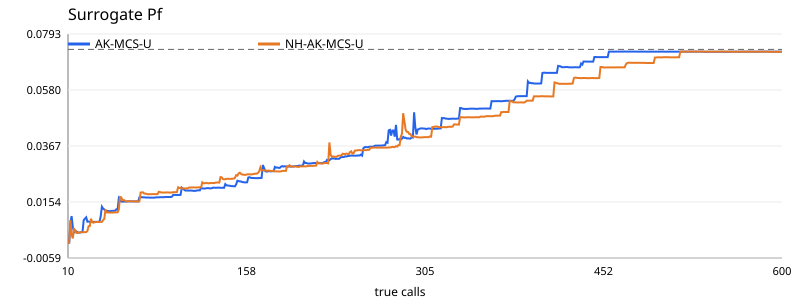

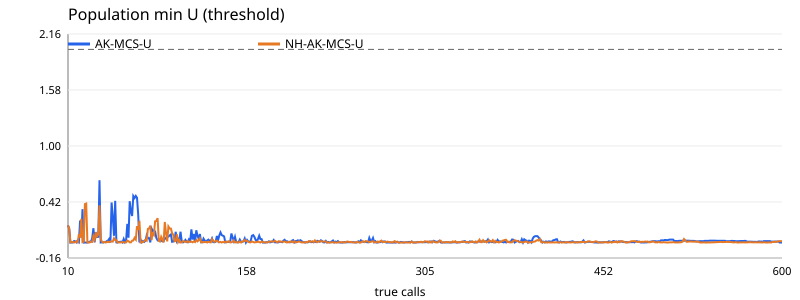

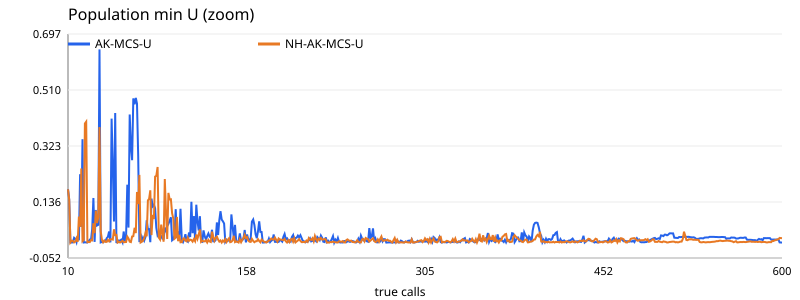

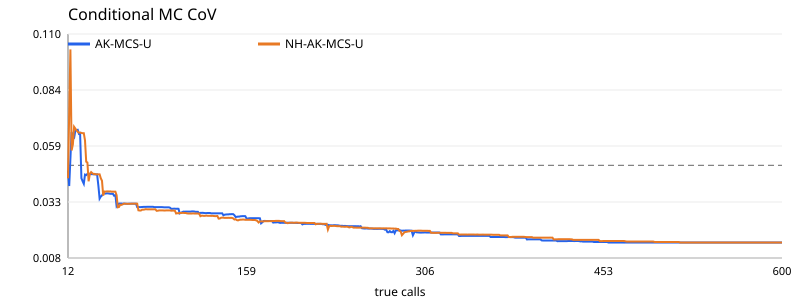

In [17]:
pf_svg = line_chart("Surrogate Pf", "pf_surrogate", paper.get("reported_pf"), 4)
u_svg = line_chart("Population min U (threshold)", "population_min_u", stop["min_u"], 2)
u_zoom_svg = line_chart("Population min U (zoom)", "population_min_u", None, 3)
cov_svg = line_chart("Conditional MC CoV", "mc_cov", stop["max_mc_cov"], 3)

## 같은 예산에서 직접 비교

최종 호출 수가 같더라도, 아래 표는 두 평가 로그에 공통으로 존재하는 호출 수만 사용합니다. `Δ Pf`와 `Δ min U`는 NH − reference입니다.

In [18]:
milestones = sorted(set([common_calls[0], common_calls[len(common_calls)//4], common_calls[len(common_calls)//2], common_calls[3*len(common_calls)//4], common_calls[-1]]))
table(["true calls", "reference Pf", "NH Pf", "Δ Pf", "reference min U", "NH min U", "Δ min U"], [
    (n,
     fmt(trajectories["reference"][n]["pf_surrogate"]),
     fmt(trajectories["nh"][n]["pf_surrogate"]),
     fmt(trajectories["nh"][n]["pf_surrogate"] - trajectories["reference"][n]["pf_surrogate"]),
     fmt(trajectories["reference"][n]["population_min_u"], 3),
     fmt(trajectories["nh"][n]["population_min_u"], 3),
     fmt(trajectories["nh"][n]["population_min_u"] - trajectories["reference"][n]["population_min_u"], 3))
    for n in milestones
])

true calls,reference Pf,NH Pf,Δ Pf,reference min U,NH min U,Δ min U
10,0.00000,0.00000,0.00000,0.178,0.178,0.000
157,0.02287,0.02577,0.00290,0.001,0.015,0.014
305,0.04332,0.04010,-0.00322,0.003,0.014,0.011
453,0.07048,0.06655,-0.00393,0.004,0.003,-0.001
600,0.07255,0.07252,-0.00003,0.000,0.014,0.014


## 실제 g 기반 신뢰성 평가
종료 조건과 별도로, 공통 true-call 수에서 저장된 OrdinaryKriging 모델을 복원합니다. theta를 재최적화하지 않으며 beta·분산·목적함수를 로그와 대조합니다.

새 독립 평가점 `N_TEST=60,000`개를 두 방법에 공통 사용합니다. 추가 독립 MCS `N_REFERENCE=1,000,000`개로 기준 고장확률을 추정하고 95% Wilson 구간을 표시합니다. 이 값도 유한 표본 추정값이며 논문의 Pf를 정답으로 사용하지 않습니다. 아래 설정을 바꾸면 평가 해상도를 조정할 수 있습니다.

- **Pf 상대오차**: 독립 기준 MCS 대비 오차. surrogate 오차와 평가용 MCS 표본오차가 함께 포함됩니다.
- **같은 평가점 Pf 상대오차**: 동일 좌표의 실제 g와 예측 평균 부호로 계산한 Pf 차이. 평가 좌표 차이에 따른 잡음을 줄이지만, 반대 방향 오분류가 상쇄될 수 있습니다.
- **고장영역 오분류 확률**: 전체 평가점 중 실제/예측 고장 여부가 다른 비율.
- **고장 누락률(FNR)**: 실제 고장점 중 안전으로 예측한 비율. **False alarm(FPR)**은 실제 안전점 중 고장으로 예측한 비율이며 분모가 다릅니다.
- **평균 Phi(-U)**: Gaussian 예측 가정하의 모델 내부 부호 불확실성. 실제 오분류와 함께 비교하며 정확도 보증으로 해석하지 않습니다.

입력분포 N(0,I)에서 표본을 뽑으므로 추가 밀도 가중치는 사용하지 않습니다. 평가용 g 호출은 별도 비용으로 보고하며 학습 데이터·run 로그에 넣지 않습니다. 현재의 저렴한 해석함수용 분석입니다. 점이 드문 희귀 고장에서는 평가 표본을 확대해야 하며, 고장 표본이 0개이면 상대오차·누락률은 미정의로 표시합니다.

참고: [신뢰성 알고리즘의 정확도·비용·반복성 평가](https://arxiv.org/abs/2305.19885), [Phi(-U) 및 active learning benchmark](https://arxiv.org/abs/2106.01713).


In [19]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr
from scipy.stats import norm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from g import Problem
from metamodels.ordinary_kriging import OrdinaryKriging

N_TEST = 60_000
N_REFERENCE = 1_000_000
TEST_SEED = 2026101801
REFERENCE_SEED = 2026101802
CALL_STEP = 100
METRIC_DIR = ROOT / "artifacts" / "analyze" / RUN_DIR.name
METRIC_DIR.mkdir(parents=True, exist_ok=True)
assert N_TEST > 0 and N_REFERENCE > 0 and CALL_STEP > 0
assert TEST_SEED != REFERENCE_SEED
assert ref["config"]["problem"] == nh["config"]["problem"], "두 run의 문제 정의가 다릅니다."
assert ref["config"]["problem"]["factory"] == "g:Problem", "이 분석은 내장 해석함수용입니다."
for run in runs.values():
    assert run["config"]["metamodel"]["factory"] == "metamodels.ordinary_kriging:OrdinaryKriging"

problem = Problem(ref["config"]["problem"])
def true_values(points):
    values = np.fromiter((problem.g(x) for x in points), dtype=float, count=len(points))
    assert np.isfinite(values).all()
    return values

def wilson_interval(k, n):
    z = norm.ppf(.975)
    p = k / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return max(0., center-half), min(1., center+half)

truth_started = time.perf_counter()
test_x = np.random.default_rng(TEST_SEED).standard_normal((N_TEST, problem.d))
test_g = true_values(test_x)
test_failure = test_g <= 0
test_failures = int(test_failure.sum())
pf_test_true = test_failures / N_TEST
test_keys = set(map(tuple, test_x))
for run in runs.values():
    assert test_keys.isdisjoint(tuple(c["x"]) for c in run["g_calls"]), "評価点が学習点と重複しています。"
del test_keys

reference_rng = np.random.default_rng(REFERENCE_SEED)
reference_failures = 0
for start in range(0, N_REFERENCE, 100_000):
    pts = reference_rng.standard_normal((min(100_000, N_REFERENCE-start), problem.d))
    reference_failures += int((true_values(pts) <= 0).sum())
pf_reference = reference_failures / N_REFERENCE
reference_ci = wilson_interval(reference_failures, N_REFERENCE)
reference_cov = np.sqrt((1-pf_reference)/(N_REFERENCE*pf_reference)) if pf_reference else None
truth_seconds = time.perf_counter() - truth_started
np.savez_compressed(METRIC_DIR / "test_truth.npz", X=test_x, g=test_g)
provenance = {
    "run_dir": str(RUN_DIR.resolve()), "problem": ref["config"]["problem"],
    "g_source_sha256": sha256(ROOT / "g.py"),
    "run_sources": {mode: {name: sha256(RUN_DIR / mode / name)
                          for name in ("effective_config.json", "g_calls.jsonl", "evaluation.jsonl")}
                    for mode in MODES},
    "test_seed": TEST_SEED, "reference_seed": REFERENCE_SEED,
    "rng": "numpy.default_rng", "numpy_version": np.__version__,
    "n_test": N_TEST, "n_reference": N_REFERENCE,
    "test_failures": test_failures, "reference_failures": reference_failures,
    "pf_test_true": pf_test_true, "pf_reference": pf_reference,
    "reference_mc_95_wilson": reference_ci, "reference_mc_cov": reference_cov,
    "offline_true_calls": N_TEST + N_REFERENCE, "truth_seconds": truth_seconds,
}
table(["기준", "표본 수", "고장 수", "Pf", "95% Wilson MC interval"], [
    ("Common test", N_TEST, test_failures, fmt(pf_test_true, 7),
     " – ".join(fmt(v, 7) for v in wilson_interval(test_failures, N_TEST))),
    ("Independent reference MCS", N_REFERENCE, reference_failures, fmt(pf_reference, 7),
     " – ".join(fmt(v, 7) for v in reference_ci)),
])
print(f"별도 평가용 g 호출: {N_TEST + N_REFERENCE:,}; 계산 시간: {truth_seconds:.2f}s")
print(f"기준 MCS CoV: {fmt(reference_cov, 6)}. 학습 true-call 예산에는 포함하지 않습니다.")


기준,표본 수,고장 수,Pf,95% Wilson MC interval
Common test,60000,4409,0.0734833,0.0714227 – 0.0755986
Independent reference MCS,1000000,72911,0.0729110,0.0724031 – 0.0734222


별도 평가용 g 호출: 1,060,000; 계산 시간: 1.03s
기준 MCS CoV: 0.003566. 학습 true-call 예산에는 포함하지 않습니다.


In [20]:
def classification_metrics(truth, predicted):
    truth, predicted = np.asarray(truth, bool), np.asarray(predicted, bool)
    assert truth.shape == predicted.shape and truth.ndim == 1 and truth.size
    n = truth.size
    nf = int(truth.sum())
    fn = int((truth & ~predicted).sum())
    fp = int((~truth & predicted).sum())
    delta = float(predicted.mean() - truth.mean())
    assert np.isclose(delta, (fp-fn)/n)
    return {
        "false_negative_count": fn, "false_positive_count": fp,
        "pf_test_prediction": float(predicted.mean()),
        "pf_signed_error_same_set": delta,
        "pf_relative_error_same_set": abs(fp-fn)/nf if nf else None,
        "region_error": (fp+fn)/n,
        "region_error_relative_to_failure": (fp+fn)/nf if nf else None,
        "failure_miss_rate": fn/nf if nf else None,
        "false_alarm_rate": fp/(n-nf) if nf < n else None,
    }

# Independent checks: cancellation, perfect classification, and empty failure class.
toy = classification_metrics([True, True, False, False], [False, True, True, False])
assert toy["pf_relative_error_same_set"] == 0 and toy["region_error"] == .5
assert toy["failure_miss_rate"] == .5 and toy["false_alarm_rate"] == .5
assert classification_metrics([True, False], [True, False])["region_error"] == 0
assert classification_metrics([False, False], [False, True])["failure_miss_rate"] is None
assert classification_metrics([True, True], [False, True])["false_alarm_rate"] is None

checkpoints = sorted({common_calls[0], common_calls[-1]} |
                     {n for n in common_calls if n % CALL_STEP == 0})
metric_rows = []
restore_started = time.perf_counter()
for mode, run in runs.items():
    for n in checkpoints:
        row = trajectories[mode][n]
        calls = run["g_calls"][:n]
        assert len(calls) == n and all(c["status"] == "ok" for c in calls)
        model_cfg = dict(run["config"]["metamodel"],
                         theta=row["training_log"]["theta"], optimize=False)
        fitted = OrdinaryKriging(model_cfg)
        fitted.fit([c["x"] for c in calls], [c["y"] for c in calls])
        for key in ("beta", "process_variance", "objective"):
            np.testing.assert_allclose(fitted.training_log[key], row["training_log"][key],
                                       rtol=1e-7, atol=1e-7, err_msg=f"{mode}, {n}: {key}")
        mu, variance = fitted.predict_moments(test_x)
        assert np.isfinite(mu).all() and np.isfinite(variance).all() and (variance > 0).all()
        metrics = classification_metrics(test_failure, mu <= 0)
        metrics.update(
            mode=mode, n_true_calls=n, model_snapshot=row["model_snapshot"],
            pf_relative_error_reference=(abs(metrics["pf_test_prediction"]-pf_reference)/pf_reference
                                         if pf_reference else None),
            mean_misclassification_probability=float(ndtr(-np.abs(mu)/np.sqrt(variance)).mean()),
            fraction_u_below_2=float((np.abs(mu)/np.sqrt(variance) < 2).mean()),
        )
        metric_rows.append(metrics)
    print(f"{MODES[mode]}: {len(checkpoints)}개 snapshot 복원·평가 완료")
provenance.update(checkpoints=checkpoints, restoration_and_prediction_seconds=time.perf_counter()-restore_started)
(METRIC_DIR / "reliability_metrics.json").write_text(
    json.dumps({"provenance": provenance, "metrics": metric_rows}, indent=2, allow_nan=False), encoding="utf-8")
print("결과 저장:", METRIC_DIR)


AK-MCS-U: 7개 snapshot 복원·평가 완료
NH-AK-MCS-U: 7개 snapshot 복원·평가 완료
결과 저장: c:\Users\user\Desktop\LAB\NH-AL\NH-AL\artifacts\analyze\gp_holdout_01


In [21]:
def pct(value, digits=3):
    return "—" if value is None else f"{100*value:.{digits}f}%"

table(["true calls", "모드", "test Pf", "Pf 오차 / 독립 기준",
       "Pf 오차 / 같은 점", "영역 오분류", "고장 누락 FNR", "False alarm FPR", "평균 Phi(-U)"],
      [(r["n_true_calls"], MODES[r["mode"]], fmt(r["pf_test_prediction"], 6),
        pct(r["pf_relative_error_reference"]), pct(r["pf_relative_error_same_set"]),
        pct(r["region_error"]), pct(r["failure_miss_rate"]), pct(r["false_alarm_rate"]),
        pct(r["mean_misclassification_probability"]))
       for r in sorted(metric_rows, key=lambda r: (r["n_true_calls"], r["mode"]))])
print("모든 지표는 새 공통 test set 기준입니다. 원래 run의 integration Pf와 표본이 달라 수치가 다를 수 있습니다.")
print("독립 기준 대비 Pf 오차에는 양쪽 MCS 표본오차가 포함됩니다. 같은 점 대비 오차도 모집단의 정확한 오차는 아닙니다.")


true calls,모드,test Pf,Pf 오차 / 독립 기준,Pf 오차 / 같은 점,영역 오분류,고장 누락 FNR,False alarm FPR,평균 Phi(-U)
10,NH-AK-MCS-U,0.000000,100.000%,100.000%,7.348%,100.000%,0.000%,7.224%
10,AK-MCS-U,0.000000,100.000%,100.000%,7.348%,100.000%,0.000%,7.224%
100,NH-AK-MCS-U,0.019133,73.758%,73.962%,5.435%,73.962%,0.000%,2.518%
100,AK-MCS-U,0.018283,74.924%,75.119%,5.527%,75.164%,0.004%,3.215%
200,NH-AK-MCS-U,0.029150,60.020%,60.331%,4.460%,60.513%,0.014%,4.738%
200,AK-MCS-U,0.030167,58.625%,58.948%,4.358%,59.129%,0.014%,3.899%
300,NH-AK-MCS-U,0.041717,42.784%,43.230%,3.243%,43.683%,0.036%,2.126%
300,AK-MCS-U,0.044400,39.104%,39.578%,3.098%,40.871%,0.103%,2.419%
400,NH-AK-MCS-U,0.057517,21.114%,21.728%,1.633%,21.978%,0.020%,1.451%
400,AK-MCS-U,0.061533,15.605%,16.262%,1.218%,16.421%,0.013%,1.350%


모든 지표는 새 공통 test set 기준입니다. 원래 run의 integration Pf와 표본이 달라 수치가 다를 수 있습니다.
독립 기준 대비 Pf 오차에는 양쪽 MCS 표본오차가 포함됩니다. 같은 점 대비 오차도 모집단의 정확한 오차는 아닙니다.


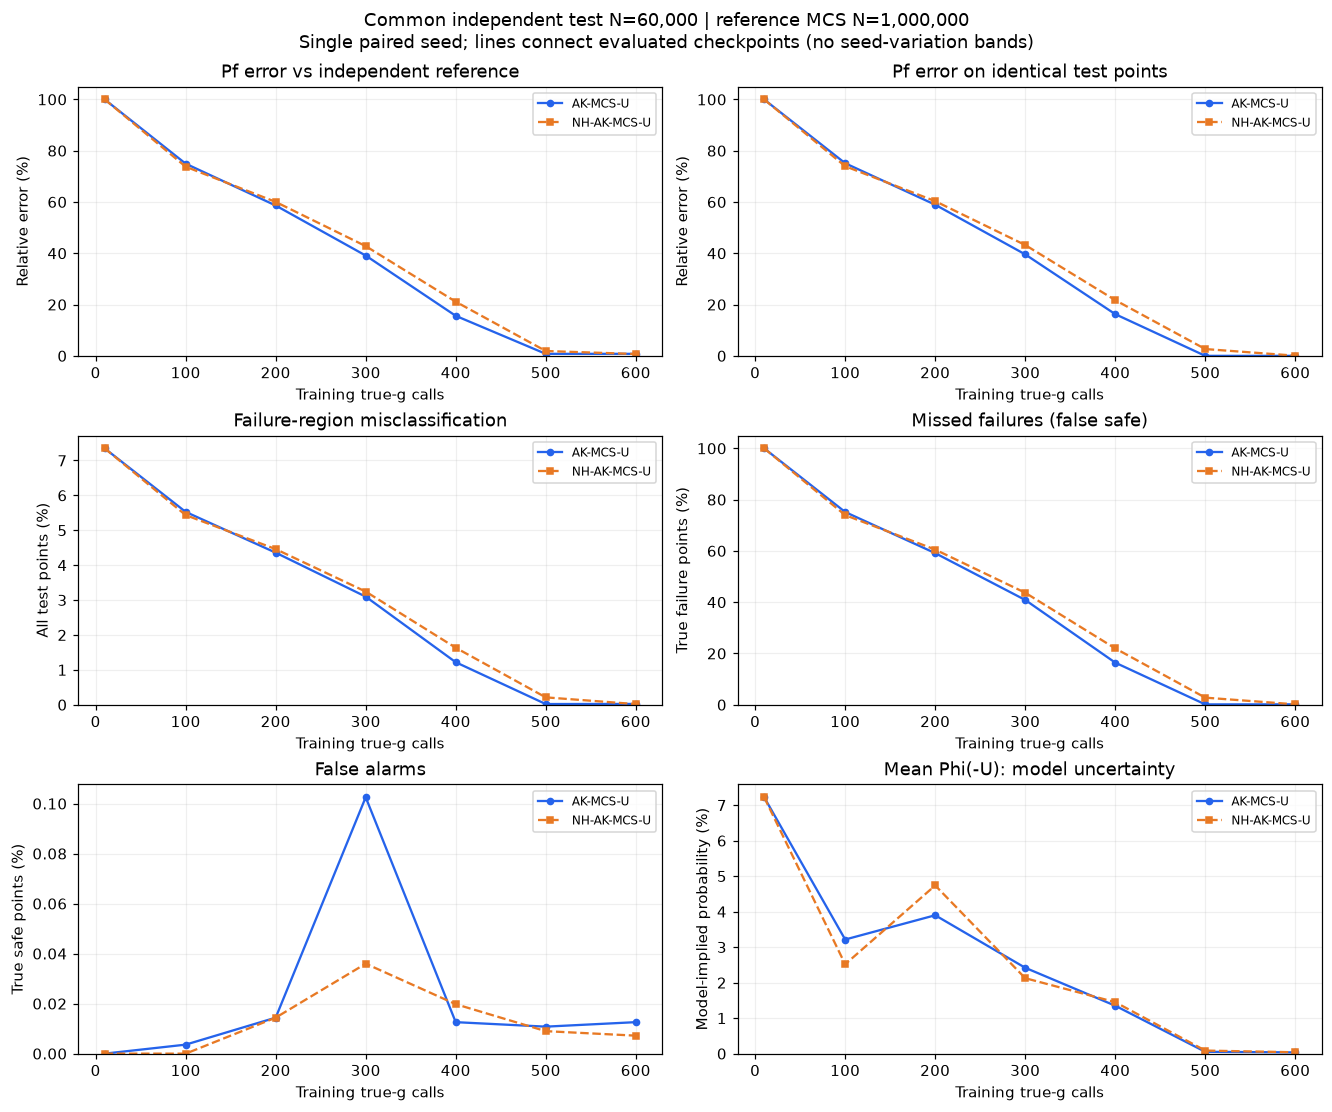

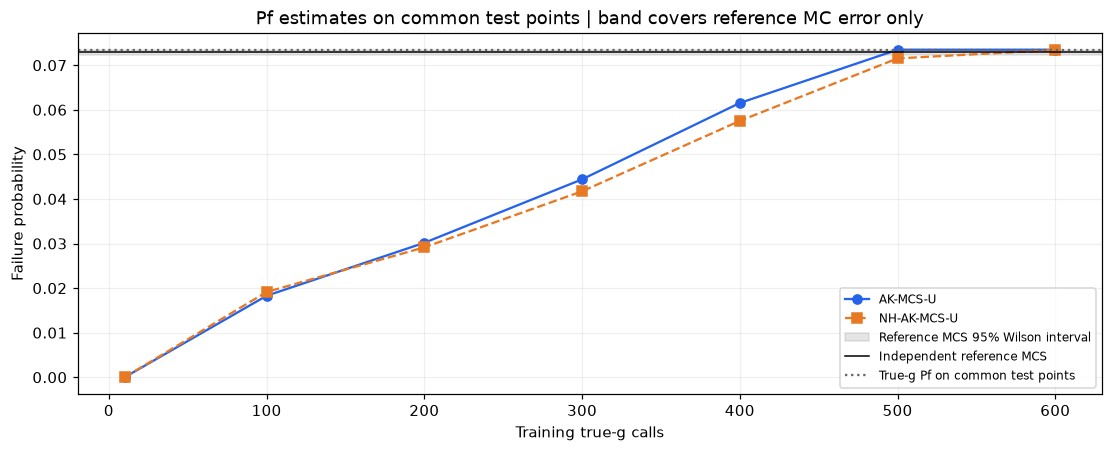

In [22]:
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
panels = [
    ("pf_relative_error_reference", "Pf error vs independent reference", "Relative error (%)"),
    ("pf_relative_error_same_set", "Pf error on identical test points", "Relative error (%)"),
    ("region_error", "Failure-region misclassification", "All test points (%)"),
    ("failure_miss_rate", "Missed failures (false safe)", "True failure points (%)"),
    ("false_alarm_rate", "False alarms", "True safe points (%)"),
    ("mean_misclassification_probability", "Mean Phi(-U): model uncertainty", "Model-implied probability (%)"),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    for mode, style, marker in (("reference", "-", "o"), ("nh", "--", "s")):
        rows = [r for r in metric_rows if r["mode"] == mode]
        ys = [100*r[key] if r[key] is not None else np.nan for r in rows]
        ax.plot([r["n_true_calls"] for r in rows], ys, linestyle=style, marker=marker,
                ms=4, color=COLORS[mode], label=MODES[mode])
    ax.set(title=title, xlabel="Training true-g calls", ylabel=ylabel)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle(f"Common independent test N={N_TEST:,} | reference MCS N={N_REFERENCE:,}\n"
             "Single paired seed; lines connect evaluated checkpoints (no seed-variation bands)",
             fontsize=12)
fig.savefig(METRIC_DIR / "reliability_metrics.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for mode, style in (("reference", "-o"), ("nh", "--s")):
    rows = [r for r in metric_rows if r["mode"] == mode]
    ax.plot([r["n_true_calls"] for r in rows], [r["pf_test_prediction"] for r in rows],
            style, color=COLORS[mode], label=MODES[mode])
ax.axhspan(*reference_ci, color="gray", alpha=.2, label="Reference MCS 95% Wilson interval")
ax.axhline(pf_reference, color="black", lw=1, label="Independent reference MCS")
ax.axhline(pf_test_true, color="#666666", ls=":", label="True-g Pf on common test points")
ax.set(xlabel="Training true-g calls", ylabel="Failure probability",
       title="Pf estimates on common test points | band covers reference MC error only")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
fig.savefig(METRIC_DIR / "failure_probability_reference.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


In [23]:
last_n = checkpoints[-1]
final_metrics = {mode: next(r for r in metric_rows if r["mode"] == mode and r["n_true_calls"] == last_n)
                 for mode in MODES}
print(f"공통 최종 예산 {last_n}회, 실제 test 고장점 {test_failures:,}/{N_TEST:,}:")
for mode, r in final_metrics.items():
    print(f"{MODES[mode]}: FN={r['false_negative_count']}, FP={r['false_positive_count']}; "
          f"영역 오분류={pct(r['region_error'])}, 고장 누락률={pct(r['failure_miss_rate'])}, "
          f"같은 점 Pf 상대오차={pct(r['pf_relative_error_same_set'])}")
print("Pf 차이는 (FP − FN)/N, 영역 오분류는 (FP + FN)/N입니다. Pf 오차가 작아도 상쇄 여부를 함께 확인하세요.")
print("각 오분류 1개는 전체 test에서 1/N_TEST의 확률질량을 나타냅니다. 작은 개수 차이를 단일 seed의 우위로 단정하지 않습니다.")
print("평균 Phi(-U)는 모델 내부 진단이며 실제 오류와 불일치할 수 있습니다. seed 반복실험은 수행하지 않았습니다.")


공통 최종 예산 600회, 실제 test 고장점 4,409/60,000:
AK-MCS-U: FN=7, FP=7; 영역 오분류=0.023%, 고장 누락률=0.159%, 같은 점 Pf 상대오차=0.000%
NH-AK-MCS-U: FN=7, FP=4; 영역 오분류=0.018%, 고장 누락률=0.159%, 같은 점 Pf 상대오차=0.068%
Pf 차이는 (FP − FN)/N, 영역 오분류는 (FP + FN)/N입니다. Pf 오차가 작아도 상쇄 여부를 함께 확인하세요.
각 오분류 1개는 전체 test에서 1/N_TEST의 확률질량을 나타냅니다. 작은 개수 차이를 단일 seed의 우위로 단정하지 않습니다.
평균 Phi(-U)는 모델 내부 진단이며 실제 오류와 불일치할 수 있습니다. seed 반복실험은 수행하지 않았습니다.


## 해석 메모

- 실제 g 기반 독립 평가를 추가했습니다. 기준 MCS도 유한 표본 추정값이므로 MC 구간과 같은 평가점에서의 오분류를 함께 해석하세요.
- `min U < 2`이면 지정한 학습 수렴 기준을 만족하지 못한 것입니다. 호출 예산에 도달해 끝난 것과 수렴은 구분해야 합니다.
- 논문의 `Pf=0.0734`와 호출 수는 참고선입니다. 현재 설정의 초기 설계·최적화 등은 논문의 엄밀한 재현 조건과 다릅니다.
- 단일 seed의 paired 결과입니다. NH의 평균적 우위나 안정성을 주장하려면 여러 seed의 독립 반복이 필요합니다.